<a href="https://colab.research.google.com/github/RDM06/CRM_Coursework/blob/main/6BUIS017C_1_CRM_CM_BI_CW1_RachelMerrion_20232740.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CRM Coursework — S&P 500 Stock Segmentation

## 1. Setup and reproducibility

In Colab, install the required packages if needed. Place the existing cache inside `/content/crm_outputs/cache` before running. For a GitHub snapshot, copy the repository cache into that folder. Legacy caches may have an unknown ticker retrieval date; do not substitute the current date.

In [1]:
# In Google Colab, uncomment if required:
%pip install yfinance lxml html5lib beautifulsoup4

import json
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

# ------------------------------------------------------------
# PROJECT FOLDER STRUCTURE
# ------------------------------------------------------------
PROJECT = Path("/content/crm_outputs")
CACHE = PROJECT / "cache"
RAW_CACHE = CACHE / "raw"
METADATA_DIR = CACHE / "metadata"
TABLES = PROJECT / "outputs" / "tables"
FIGURES = PROJECT / "outputs" / "figures"
CLUSTER_OUTPUTS = PROJECT / "outputs" / "clustering"

for folder in [RAW_CACHE, METADATA_DIR, TABLES, FIGURES, CLUSTER_OUTPUTS]:
    folder.mkdir(parents=True, exist_ok=True)

START = "2021-01-01"
END = "2025-01-01"  # exclusive
RANDOM_STATE = 42

# Set True to reuse the last successful cached download.
# Set False to download fresh data and overwrite the cache.
USE_CACHE = True

# Cache file names are deliberately consistent.
CACHE_FILES = {
    "close": RAW_CACHE / "close.csv",
    "volume": RAW_CACHE / "volume.csv",
    "adjusted_close": RAW_CACHE / "adjusted_close.csv",
    "stock_splits": RAW_CACHE / "stock_splits.csv",
    "dividends": RAW_CACHE / "dividends.csv",
    "constituents": RAW_CACHE / "constituents.csv",
    "manifest": METADATA_DIR / "cache_manifest.json",
}

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__)
print("yfinance:", yf.__version__, "| scikit-learn:", sklearn.__version__)
print("scipy:", scipy.__version__)
print("Project directory:", PROJECT.resolve())
print("USE_CACHE:", USE_CACHE)

Python: 3.13.18
pandas: 2.2.3 | numpy: 2.4.6
yfinance: 0.2.66 | scikit-learn: 1.6.1
scipy: 1.16.3
Project directory: /content/crm_outputs
USE_CACHE: True


## 2. Retrieve the S&P 500 ticker universe

The constituent list is retrieved from Wikipedia. A timestamp is stored so the ticker universe can be described in the report.

In [2]:
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
# Read provenance before deciding whether to reuse the cache.
cache_manifest = {}
if CACHE_FILES["manifest"].exists():
    with open(CACHE_FILES["manifest"], encoding="utf-8") as f:
        cache_manifest = json.load(f)

required_cache = ["constituents", "close", "volume", "adjusted_close", "manifest"]
active_cache_mode = USE_CACHE and all(CACHE_FILES[k].exists() for k in required_cache)
if active_cache_mode:
    if (cache_manifest.get("study_start") != START or
        cache_manifest.get("study_end_exclusive") != END or
        cache_manifest.get("benchmark") != "^GSPC" or
        cache_manifest.get("auto_adjust") is not False):
        raise ValueError("Cache settings do not match the study. Set USE_CACHE=False to refresh.")
retrieved_at_utc = None

if active_cache_mode:
    retrieved_at_utc = cache_manifest.get("ticker_retrieved_at_utc")
    if retrieved_at_utc is None:
        warnings.warn("Original ticker retrieval date is unknown in this legacy cache.")
    sp500 = pd.read_csv(CACHE_FILES["constituents"])
    print("Loaded cached constituent list.")
else:
    tables = pd.read_html(
        WIKI_URL,
        storage_options={"User-Agent": "Mozilla/5.0"}
    )
    sp500 = tables[0].copy()
    sp500["Share"] = sp500["Symbol"].astype(str).str.replace(".", "-", regex=False)
    sp500[["Symbol", "Security", "GICS Sector", "Share"]].to_csv(
        CACHE_FILES["constituents"], index=False
    )
    retrieved_at_utc = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC")
    print("Retrieved and cached current constituent list.")

# Recreate ticker and sector structures consistently.
if "Share" not in sp500.columns:
    sp500["Share"] = sp500["Symbol"].astype(str).str.replace(".", "-", regex=False)

sp500 = sp500.drop_duplicates(subset="Share").copy()
tickers = sp500["Share"].dropna().tolist()
sector_map = sp500.set_index("Share")["GICS Sector"]

display(sp500[["Share", "Security", "GICS Sector"]].head())
print("Ticker count:", len(tickers))
print("Ticker list retrieved at (UTC):", retrieved_at_utc or "Unknown")
if active_cache_mode and cache_manifest.get("tickers_requested") != len(tickers):
    raise ValueError("Cached ticker count does not match manifest.")
if active_cache_mode and "ticker_symbols" in cache_manifest and cache_manifest["ticker_symbols"] != tickers:
    raise ValueError("Cached ticker list does not match manifest.")

Loaded cached constituent list.


,Share,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology


Ticker count: 503
Ticker list retrieved at (UTC): 2026-11-24 17:25:33 UTC


## 3. Load or download daily market data

### Cache layout

```text
crm_project/
├── cache/
│   ├── raw/
│   │   ├── close.csv
│   │   ├── volume.csv
│   │   ├── adjusted_close.csv
│   │   ├── stock_splits.csv
│   │   ├── dividends.csv
│   │   └── constituents.csv
│   └── metadata/
│       └── cache_manifest.json
└── outputs/
    ├── tables/
    ├── figures/
    └── clustering/
```

When `USE_CACHE = True`, all required cached price/volume files must exist. When `False`, the notebook downloads the data and refreshes the cache. The cache is stored as CSV for transparency and easy inspection.

In [3]:
def normalise_daily_index(frame):
    """Return a copy with a timezone-naive, normalized, sorted date index."""
    frame = frame.copy()
    idx = pd.to_datetime(frame.index)
    if getattr(idx, "tz", None) is not None:
        idx = idx.tz_localize(None)
    frame.index = idx.normalize()
    frame = frame.sort_index()
    return frame

def read_cached_table(path):
    if not path.exists():
        raise FileNotFoundError(
            f"Required cache file is missing: {path}. "
            "Set USE_CACHE=False to download and create a fresh cache."
        )
    return normalise_daily_index(pd.read_csv(path, index_col=0, parse_dates=True))

# Use the same cache decision as the constituent-list cell.
if USE_CACHE and not active_cache_mode:
    print("Incomplete cache; downloading a fresh snapshot.")

if active_cache_mode:
    close = read_cached_table(CACHE_FILES["close"])
    volume = read_cached_table(CACHE_FILES["volume"])
    adj = read_cached_table(CACHE_FILES["adjusted_close"])

    stock_splits = (
        read_cached_table(CACHE_FILES["stock_splits"])
        if CACHE_FILES["stock_splits"].exists() else None
    )
    dividends = (
        read_cached_table(CACHE_FILES["dividends"])
        if CACHE_FILES["dividends"].exists() else None
    )

    if CACHE_FILES["manifest"].exists():
        with open(CACHE_FILES["manifest"], "r", encoding="utf-8") as f:
            cache_manifest = json.load(f)
        print("Loaded cache manifest:")
        print(json.dumps(cache_manifest, indent=2))
    else:
        cache_manifest = {}
        warnings.warn("No cache manifest found. Record the source and retrieval date before submission.")

    data_source_mode = "Loaded existing cache"

else:
    all_symbols = tickers + ["^GSPC"]
    raw = yf.download(
        all_symbols,
        start=START,
        end=END,
        auto_adjust=False,
        actions=True,
        progress=False,
        threads=False,
        group_by="column"
    )

    if raw.empty:
        raise RuntimeError("No market data downloaded. Check access or use a valid cached snapshot.")

    fields = raw.columns.get_level_values(0)
    required_fields = ["Close", "Volume", "Adj Close"]
    missing_fields = [field for field in required_fields if field not in fields]
    if missing_fields:
        raise RuntimeError(f"Yahoo download is missing required fields: {missing_fields}")

    close = normalise_daily_index(raw["Close"])
    volume = normalise_daily_index(raw["Volume"])
    adj = normalise_daily_index(raw["Adj Close"])

    stock_splits = normalise_daily_index(raw["Stock Splits"]) if "Stock Splits" in fields else None
    dividends = normalise_daily_index(raw["Dividends"]) if "Dividends" in fields else None

    close.to_csv(CACHE_FILES["close"])
    volume.to_csv(CACHE_FILES["volume"])
    adj.to_csv(CACHE_FILES["adjusted_close"])

    if stock_splits is not None:
        stock_splits.to_csv(CACHE_FILES["stock_splits"])
    else:
        CACHE_FILES["stock_splits"].unlink(missing_ok=True)
    if dividends is not None:
        dividends.to_csv(CACHE_FILES["dividends"])
    else:
        CACHE_FILES["dividends"].unlink(missing_ok=True)

    cache_manifest = {
        "provider": "Yahoo Finance via yfinance",
        "retrieved_at_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC"),
        "ticker_retrieved_at_utc": retrieved_at_utc,
        "ticker_symbols": tickers,
        "study_start": START,
        "study_end_exclusive": END,
        "tickers_requested": len(tickers),
        "benchmark": "^GSPC",
        "auto_adjust": False,
        "actions_downloaded": stock_splits is not None and dividends is not None,
        "files": {key: str(path) for key, path in CACHE_FILES.items() if key != "manifest"}
    }
    with open(CACHE_FILES["manifest"], "w", encoding="utf-8") as f:
        json.dump(cache_manifest, f, indent=2)

    data_source_mode = "Fresh Yahoo Finance download; cache refreshed"

print("Data mode:", data_source_mode)
print("Daily rows:", len(adj))
print("Date range:", adj.index.min().date(), "to", adj.index.max().date())
print("Close shape:", close.shape, "| Volume shape:", volume.shape, "| Adj Close shape:", adj.shape)

# Basic field consistency checks.
for label, frame in [("Close", close), ("Volume", volume), ("Adj Close", adj)]:
    if not frame.index.equals(adj.index):
        print(f"Note: {label} and adjusted-close indexes differ; alignment will be explicit in validation.")

print("Market data retrieved at (UTC):", cache_manifest.get("retrieved_at_utc", "Unknown"))
for frame in [close, volume, adj]:
    if frame.empty or frame.index.min() < pd.Timestamp(START) or frame.index.max() >= pd.Timestamp(END):
        raise ValueError("Cached observations fall outside the requested study period or are empty.")

Loaded cache manifest:
{
  "provider": "Yahoo Finance via yfinance",
  "retrieved_at_utc": "2026-11-24 17:26:46 UTC",
  "ticker_retrieved_at_utc": "2026-11-24 17:25:33 UTC",
  "ticker_symbols": [
    "MMM",
    "AOS",
    "ABT",
    "ABBV",
    "ACN",
    "ADBE",
    "AMD",
    "AES",
    "AFL",
    "A",
    "APD",
    "ABNB",
    "AKAM",
    "ALB",
    "ARE",
    "ALGN",
    "ALLE",
    "LNT",
    "ALL",
    "GOOGL",
    "GOOG",
    "MO",
    "AMZN",
    "AMCR",
    "AEE",
    "AEP",
    "AXP",
    "AIG",
    "AMT",
    "AWK",
    "AMP",
    "AME",
    "AMGN",
    "APH",
    "ADI",
    "AON",
    "APA",
    "APO",
    "AAPL",
    "AMAT",
    "APP",
    "APTV",
    "ACGL",
    "ADM",
    "ARES",
    "ANET",
    "AJG",
    "AIZ",
    "T",
    "ATO",
    "ADSK",
    "ADP",
    "AZO",
    "AVY",
    "AXON",
    "BKR",
    "BALL",
    "BAC",
    "BAX",
    "BDX",
    "BRK-B",
    "BBY",
    "TECH",
    "BIIB",
    "BLK",
    "BX",
    "XYZ",
    "BE",
    "BNY",
    "BA",
    "BKNG",
    "

## 4. Validate dates, prices, volume and histories (Task 1.2)

This section applies a **complete benchmark-calendar coverage** rule. It records inclusion/exclusion reasons and saves the log. This rule may exclude otherwise valid companies with isolated gaps or shorter listing histories. Corporate-action counts and split-day observations are audited below as well.

In [4]:
tables = {"Adjusted Close": adj, "Close": close, "Volume": volume}

for name, frame in tables.items():
    duplicate_dates = int(frame.index.duplicated().sum())
    duplicate_columns = int(frame.columns.duplicated().sum())
    print(f"{name}: duplicate dates={duplicate_dates}, duplicate columns={duplicate_columns}")
    if duplicate_dates or duplicate_columns:
        raise ValueError(f"Duplicate observations detected in {name}. Investigate before continuing.")
    if not frame.index.is_monotonic_increasing:
        raise ValueError(f"{name} index is not chronological.")

if "^GSPC" not in adj.columns:
    raise RuntimeError("Benchmark ^GSPC is missing from adjusted close.")

benchmark_daily = adj["^GSPC"].dropna()
if benchmark_daily.empty or not np.isfinite(benchmark_daily).all() or (benchmark_daily <= 0).any():
    raise RuntimeError("Benchmark has no valid observations or contains invalid prices.")

benchmark_dates = benchmark_daily.index
expected_sessions = len(benchmark_dates)

validation_records = []
valid_tickers = []

for share in tickers:
    required_tables = {"AdjClose": adj, "Close": close, "Volume": volume}
    missing_columns = [field for field, frame in required_tables.items() if share not in frame.columns]

    if missing_columns:
        validation_records.append({
            "Share": share, "ExpectedSessions": expected_sessions,
            "AdjustedCloseObservations": 0, "CloseObservations": 0,
            "VolumeObservations": 0, "MissingCells": np.nan,
            "NonFiniteValues": np.nan, "NonPositivePrices": np.nan,
            "InvalidVolume": np.nan, "Validation": "Excluded",
            "ExclusionReason": "Missing columns: " + ", ".join(missing_columns)
        })
        continue

    a = adj[share].reindex(benchmark_dates)
    c = close[share].reindex(benchmark_dates)
    v = volume[share].reindex(benchmark_dates)

    missing_cells = int((a.isna() | c.isna() | v.isna()).sum())
    non_finite = int((
        (a.notna() & ~np.isfinite(a)) |
        (c.notna() & ~np.isfinite(c)) |
        (v.notna() & ~np.isfinite(v))
    ).sum())
    non_positive_prices = int((((a <= 0) | (c <= 0)).fillna(False)).sum())
    invalid_volume_mask = v.notna() & ((v < 0) | (v % 1 != 0) | ~np.isfinite(v))
    invalid_volume = int(invalid_volume_mask.sum())

    reasons = []
    if missing_cells:
        reasons.append(f"missing_cells={missing_cells}")
    if non_finite:
        reasons.append(f"non_finite={non_finite}")
    if non_positive_prices:
        reasons.append(f"non_positive_prices={non_positive_prices}")
    if invalid_volume:
        reasons.append(f"invalid_volume={invalid_volume}")

    included = len(reasons) == 0
    if included:
        valid_tickers.append(share)

    available_dates = adj[share].dropna().index
    validation_records.append({
        "Share": share,
        "ExpectedSessions": expected_sessions,
        "AdjustedCloseObservations": int(a.notna().sum()),
        "CloseObservations": int(c.notna().sum()),
        "VolumeObservations": int(v.notna().sum()),
        "MissingCells": missing_cells,
        "NonFiniteValues": non_finite,
        "NonPositivePrices": non_positive_prices,
        "InvalidVolume": invalid_volume,
        "FirstAvailableDate": available_dates.min() if len(available_dates) else pd.NaT,
        "LastAvailableDate": available_dates.max() if len(available_dates) else pd.NaT,
        "Validation": "Included" if included else "Excluded",
        "ExclusionReason": "; ".join(reasons)
    })

validation_log = pd.DataFrame(validation_records)
validation_log.to_csv(TABLES / "validation_log.csv", index=False)
pd.Series(valid_tickers, name="Share").to_csv(TABLES / "included_shares.csv", index=False)

print("Requested:", len(tickers), "| included:", len(valid_tickers), "| excluded:", len(tickers) - len(valid_tickers))
display(validation_log["Validation"].value_counts().to_frame("Shares"))
display(validation_log.loc[validation_log["Validation"] == "Excluded", "ExclusionReason"].value_counts().head(15))
display(validation_log.head(12))

if len(valid_tickers) < 10:
    raise RuntimeError("Too few shares passed validation. Review the validation log.")

for share in valid_tickers:
    assert adj[share].reindex(benchmark_dates).notna().all()
    assert close[share].reindex(benchmark_dates).notna().all()
    assert volume[share].reindex(benchmark_dates).notna().all()

print("All retained shares have complete benchmark-date coverage:", expected_sessions, "sessions.")

# Corporate-action audit: inspect reported events without changing prices or volume.
action_summary = []
split_checks = []
for label, frame in [("Stock splits", stock_splits), ("Dividends", dividends)]:
    if frame is None:
        action_summary.append({"Action": label, "Events": np.nan, "Companies": np.nan})
        continue
    action_data = frame.reindex(index=benchmark_dates, columns=tickers)
    events = action_data.notna() & action_data.ne(0)
    action_summary.append({"Action": label, "Events": int(events.sum().sum()),
                           "Companies": int(events.any().sum())})
    if label == "Stock splits":
        for share in events.columns[events.any()]:
            if share not in close or share not in volume:
                continue
            for date in events.index[events[share]]:
                pos = benchmark_dates.get_loc(date)
                if pos == 0:
                    continue
                previous = benchmark_dates[pos - 1]
                c = close[share].reindex(benchmark_dates)
                v = volume[share].reindex(benchmark_dates)
                split_checks.append({"Share": share, "Date": date,
                    "SplitRatio": action_data.loc[date, share],
                    "CloseBefore": c.loc[previous], "CloseOnEvent": c.loc[date],
                    "VolumeBefore": v.loc[previous], "VolumeOnEvent": v.loc[date]})
action_summary = pd.DataFrame(action_summary)
split_checks = pd.DataFrame(split_checks, columns=["Share", "Date", "SplitRatio", "CloseBefore", "CloseOnEvent", "VolumeBefore", "VolumeOnEvent"])
display(action_summary)
display(split_checks.head(15))
action_summary.to_csv(TABLES / "corporate_action_summary.csv", index=False)
split_checks.to_csv(TABLES / "split_event_checks.csv", index=False)
print("Split-day observations are diagnostic only; they do not establish the provider's volume adjustment convention.")

Adjusted Close: duplicate dates=0, duplicate columns=0
Close: duplicate dates=0, duplicate columns=0
Volume: duplicate dates=0, duplicate columns=0
Requested: 503 | included: 488 | excluded: 15


,Shares
Validation,
Included,488
Excluded,15


,count
ExclusionReason,
missing_cells=1005,5
missing_cells=69,1
missing_cells=70,1
missing_cells=263,1
missing_cells=26,1
missing_cells=492,1
missing_cells=812,1
missing_cells=808,1
missing_cells=143,1


,Share,ExpectedSessions,AdjustedCloseObservations,CloseObservations,VolumeObservations,MissingCells,NonFiniteValues,NonPositivePrices,InvalidVolume,FirstAvailableDate,LastAvailableDate,Validation,ExclusionReason
0,MMM,1005,1005,1005,1005,0,0,0,0,2021-01-04,2024-12-31,Included,
1,AOS,1005,1005,1005,1005,0,0,0,0,2021-01-04,2024-12-31,Included,
2,ABT,1005,1005,1005,1005,0,0,0,0,2021-01-04,2024-12-31,Included,
3,ABBV,1005,1005,1005,1005,0,0,0,0,2021-01-04,2024-12-31,Included,
4,ACN,1005,1005,1005,1005,0,0,0,0,2021-01-04,2024-12-31,Included,
5,ADBE,1005,1005,1005,1005,0,0,0,0,2021-01-04,2024-12-31,Included,
6,AMD,1005,1005,1005,1005,0,0,0,0,2021-01-04,2024-12-31,Included,
7,AES,1005,1005,1005,1005,0,0,0,0,2021-01-04,2024-12-31,Included,
8,AFL,1005,1005,1005,1005,0,0,0,0,2021-01-04,2024-12-31,Included,
9,A,1005,1005,1005,1005,0,0,0,0,2021-01-04,2024-12-31,Included,


All retained shares have complete benchmark-date coverage: 1005 sessions.


,Action,Events,Companies
0,Stock splits,61,53
1,Dividends,6086,399


,Share,Date,SplitRatio,CloseBefore,CloseOnEvent,VolumeBefore,VolumeOnEvent
0,MMM,2024-04-01,1.196,88.687294,94.019997,5245776,13004800
1,GOOGL,2022-07-18,20.000,111.777496,109.029999,46770000,43164600
2,GOOG,2022-07-18,20.000,112.766998,109.910004,34330000,33354000
3,AMZN,2022-06-06,20.000,122.349998,124.790001,97604000,135269000
4,APH,2021-03-05,2.000,15.010000,15.390000,19024800,14359200
5,APH,2024-06-12,2.000,33.607498,34.345001,9597200,13316200
6,ANET,2021-11-18,4.000,33.020000,33.137501,6596800,8506000
7,ANET,2024-12-04,4.000,103.614998,105.430000,7181200,5845900
8,T,2022-04-11,1.324,18.232628,19.629999,73121078,157485300
9,BDX,2022-04-01,1.025,204.019028,206.367920,1526228,1723051


Split-day observations are diagnostic only; they do not establish the provider's volume adjustment convention.


## 5. Weekly returns and weekly beta (Task 1.3)

Adjusted closing prices are used for returns. Weekly prices are the last available trading observation in each Friday-labelled week. The first and last incomplete boundary weeks are excluded; the first return is then removed because it has no prior completed-week price within the selected window.

In [5]:
prices = adj.loc[benchmark_dates, valid_tickers].copy()
market_prices = adj.loc[benchmark_dates, "^GSPC"].copy()

weekly_prices = prices.resample("W-FRI").last()
weekly_market_prices = market_prices.resample("W-FRI").last()

full_week_labels = weekly_prices.index[
    (weekly_prices.index >= "2021-01-08") &
    (weekly_prices.index <= "2024-12-27")
]
weekly_prices = weekly_prices.loc[full_week_labels]
weekly_market_prices = weekly_market_prices.loc[full_week_labels]

assert weekly_prices.index.equals(weekly_market_prices.index)
if weekly_prices.isna().any().any() or weekly_market_prices.isna().any():
    raise ValueError("Missing weekly prices detected; do not fill them silently.")

weekly_returns = weekly_prices.pct_change(fill_method=None).iloc[1:]
market_returns = weekly_market_prices.pct_change(fill_method=None).iloc[1:].rename("Market")

assert weekly_returns.index.equals(market_returns.index)
if weekly_returns.isna().any().any() or market_returns.isna().any():
    raise ValueError("Missing weekly returns detected.")

weekly_returns.to_csv(TABLES / "weekly_returns.csv")
market_returns.to_csv(TABLES / "weekly_market_returns.csv")

risk_rows = []
for share in valid_tickers:
    paired = pd.concat([
        weekly_returns[share].rename("ShareReturn"),
        market_returns
    ], axis=1).dropna()

    paired_weeks = len(paired)
    beta = (
        paired["ShareReturn"].cov(paired["Market"]) / paired["Market"].var()
        if paired_weeks >= 52 and paired["Market"].var() > 0
        else np.nan
    )
    risk_rows.append({
        "Share": share,
        "MeanWeeklyReturn": weekly_returns[share].mean(),
        "WeeklyBeta": beta,
        "PairedWeeks": paired_weeks
    })

risk_table = pd.DataFrame(risk_rows).set_index("Share")
risk_table.to_csv(TABLES / "risk_return_features.csv")

print("Weekly price observations:", len(weekly_prices))
print("Weekly return observations:", len(weekly_returns))
print("First weekly price labels:", weekly_prices.index.min().date())
print("Last weekly return labels:", weekly_returns.index.max().date())
print("Paired weeks range:", risk_table["PairedWeeks"].min(), "to", risk_table["PairedWeeks"].max())
print("Shares with missing beta:", int(risk_table["WeeklyBeta"].isna().sum()))
display(risk_table.describe().round(4))

Weekly price observations: 208
Weekly return observations: 207
First weekly price labels: 2021-01-08
Last weekly return labels: 2024-12-27
Paired weeks range: 207 to 207
Shares with missing beta: 0


,MeanWeeklyReturn,WeeklyBeta,PairedWeeks
count,488.0000,488.0000,488.0
mean,0.0029,0.9739,207.0
std,0.0026,0.4066,0.0
min,-0.0045,0.0555,207.0
25%,0.0012,0.6666,207.0
50%,0.0026,0.9506,207.0
75%,0.0042,1.1793,207.0
max,0.0178,3.7786,207.0


## 6. Adapted trading-volume RFM (Task 1.4)

- **Event:** daily volume exceeds twice the mean volume of the preceding 20 trading sessions.
- **Recency:** calendar days between the observation date and the most recent qualifying event across the available study history.
- **Frequency:** qualifying-event count in the latest 60 trading sessions.
- **Monetary:** sum of `Close × Volume` in the latest 60 trading sessions.

The baseline uses `shift(1)` so the current day's volume is not included in its own threshold. Shares with no historical qualifying event retain missing Recency rather than receiving an invented value.

In [6]:
observation_date = benchmark_dates[benchmark_dates <= pd.Timestamp("2024-12-27")].max()
rfm_dates = benchmark_dates[benchmark_dates <= observation_date]

rfm_rows = []
example_daily_data = {}

for share in valid_tickers:
    daily = pd.DataFrame({
        "Close": close.loc[rfm_dates, share],
        "Volume": volume.loc[rfm_dates, share]
    })

    if daily.isna().any().any():
        raise ValueError(f"Unexpected missing RFM data for {share}.")

    daily["Previous20MeanVolume"] = (
        daily["Volume"].shift(1).rolling(window=20, min_periods=20).mean()
    )
    daily["HighVolume"] = daily["Volume"] > (2 * daily["Previous20MeanVolume"])
    daily.loc[daily["Previous20MeanVolume"].isna(), "HighVolume"] = False

    latest60 = daily.tail(60)
    if len(latest60) != 60:
        raise ValueError(f"{share} does not have 60 RFM observations.")

    event_dates = daily.index[daily["HighVolume"]]
    last_event = event_dates.max() if len(event_dates) else pd.NaT
    recency = (observation_date - last_event).days if len(event_dates) else np.nan

    rfm_rows.append({
        "Share": share,
        "Recency": recency,
        "Frequency": int(latest60["HighVolume"].sum()),
        "Monetary": float((latest60["Close"] * latest60["Volume"]).sum()),
        "RFM_Sessions": len(latest60),
        "LastHighVolumeDay": last_event,
        "TotalHistoricalEvents": len(event_dates)
    })

    if share == "AAPL":
        example_daily_data[share] = daily.copy()

rfm_table = pd.DataFrame(rfm_rows).set_index("Share")
rfm_table.to_csv(TABLES / "rfm_features.csv")

print("RFM observation date:", observation_date.date())
print("RFM window sessions:", rfm_table["RFM_Sessions"].min(), "to", rfm_table["RFM_Sessions"].max())
print("Shares with no historical event (missing Recency):", int(rfm_table["Recency"].isna().sum()))
print("Shares with zero events in latest 60 sessions:", int((rfm_table["Frequency"] == 0).sum()))
display(rfm_table[["Recency", "Frequency", "Monetary"]].describe().round(3))

assert (rfm_table["RFM_Sessions"] == 60).all()
assert (rfm_table["Frequency"] >= 0).all()
assert (rfm_table["Monetary"] >= 0).all()

RFM observation date: 2024-12-27
RFM window sessions: 60 to 60
Shares with no historical event (missing Recency): 0
Shares with zero events in latest 60 sessions: 10


,Recency,Frequency,Monetary
count,488.000,488.000,4.880000e+02
mean,16.389,2.996,3.940429e+10
std,21.303,1.327,1.290038e+11
min,0.000,0.000,1.295548e+09
25%,7.000,2.000,1.024969e+10
50%,7.000,3.000,1.669215e+10
75%,11.000,4.000,3.216528e+10
max,218.000,8.000,1.845856e+12


## 7. Worked RFM example and final common share population (Task 1.5)

The final clustering population uses the intersection of shares with valid risk/return and RFM features. This avoids comparing cluster solutions built on different share populations.

In [7]:
shares_with_events = rfm_table.index[rfm_table["Recency"].notna()].tolist()
if "AAPL" in example_daily_data:
    example_share = "AAPL"
elif shares_with_events:
    example_share = shares_with_events[0]
else:
    example_share = None

if example_share is not None:
    if example_share in example_daily_data:
        example_daily = example_daily_data[example_share]
    else:
        example_daily = pd.DataFrame({
            "Close": close.loc[rfm_dates, example_share],
            "Volume": volume.loc[rfm_dates, example_share]
        })
        example_daily["Previous20MeanVolume"] = (
            example_daily["Volume"].shift(1).rolling(20, min_periods=20).mean()
        )
        example_daily["HighVolume"] = (
            example_daily["Volume"] > 2 * example_daily["Previous20MeanVolume"]
        )
        example_daily.loc[example_daily["Previous20MeanVolume"].isna(), "HighVolume"] = False

    print("Worked example:", example_share)
    example_daily = example_daily.copy()
    example_daily["Threshold"] = 2 * example_daily["Previous20MeanVolume"]
    example_daily["DailyTradedValue"] = example_daily["Close"] * example_daily["Volume"]
    latest60 = example_daily.tail(60)
    last_event = rfm_table.loc[example_share, "LastHighVolumeDay"]
    example_summary = pd.DataFrame([{
        "Share": example_share, "ObservationDate": observation_date,
        "LatestEvent": last_event, "RecencyDays": rfm_table.loc[example_share, "Recency"],
        "WindowStart": latest60.index.min(), "WindowEnd": latest60.index.max(),
        "Frequency": int(latest60["HighVolume"].sum()),
        "Monetary": latest60["DailyTradedValue"].sum()}])
    if pd.notna(last_event):
        print("Latest qualifying event:")
        display(example_daily.loc[[last_event]].round(2))
    display(example_summary)
    display(latest60.tail(5).round(2))
    example_summary.to_csv(TABLES / "rfm_worked_example.csv", index=False)
    latest60.to_csv(TABLES / "rfm_worked_example_daily.csv")
else:
    print("No share has a qualifying historical high-volume event; Recency remains missing.")

features = (
    risk_table.join(rfm_table, how="inner")
    .join(sector_map.rename("Sector"), how="left")
)

needed = ["MeanWeeklyReturn", "WeeklyBeta", "Recency", "Frequency", "Monetary"]
before_filtering = len(features)
features[needed] = features[needed].replace([np.inf, -np.inf], np.nan)
features = features.dropna(subset=needed).copy()
features = features[features["Monetary"] >= 0].copy()

features.to_csv(TABLES / "feature_table.csv")

print("Before common-feature filtering:", before_filtering)
print("Final common clustering population:", len(features))
print("Removed due to missing/non-finite required features:", before_filtering - len(features))
display(features[needed].describe().round(4))
display(features["Sector"].value_counts(dropna=False).to_frame("Shares"))

if len(features) < 10:
    raise RuntimeError("Fewer than 10 shares remain for clustering.")

assert features.index.is_unique
assert features[needed].notna().all().all()

# Population stages: risk and RFM validity are parallel checks, not sequential filters.
downloaded = sum(all(s in f.columns and f[s].notna().any() for f in [close, volume, adj]) for s in tickers)
risk_valid = np.isfinite(risk_table[["MeanWeeklyReturn", "WeeklyBeta"]]).all(axis=1)
rfm_valid = np.isfinite(rfm_table[["Recency", "Frequency", "Monetary"]]).all(axis=1) & (rfm_table["Monetary"] >= 0)
population_summary = pd.DataFrame({"Stage": ["Requested", "Downloaded (some data in each field)", "Passed validation", "Valid risk/return", "Valid RFM", "Final common population"],
    "Stocks": [len(tickers), downloaded, len(valid_tickers), int(risk_valid.sum()), int(rfm_valid.sum()), len(features)]})
display(population_summary)
population_summary.to_csv(TABLES / "stock_population_summary.csv", index=False)

Worked example: AAPL
Latest qualifying event:


,Close,Volume,Previous20MeanVolume,HighVolume,Threshold,DailyTradedValue
Date,,,,,,
2024-12-20,254.49,147495300,45004605.0,True,90009210.0,3.753608e+10


,Share,ObservationDate,LatestEvent,RecencyDays,WindowStart,WindowEnd,Frequency,Monetary
0,AAPL,2024-12-27,2024-12-20,7,2024-10-03,2024-12-27,2,6.205790e+11


,Close,Volume,Previous20MeanVolume,HighVolume,Threshold,DailyTradedValue
Date,,,,,,
2024-12-20,254.49,147495300,45004605.0,True,90009210.0,3.753608e+10
2024-12-23,255.27,40858800,50273955.0,False,100547910.0,1.043003e+10
2024-12-24,258.20,23234700,50408480.0,False,100816960.0,5.999200e+09
2024-12-26,259.02,27237100,47062575.0,False,94125150.0,7.054953e+09
2024-12-27,255.59,42355300,46125120.0,False,92250240.0,1.082559e+10


Before common-feature filtering: 488
Final common clustering population: 488
Removed due to missing/non-finite required features: 0


,MeanWeeklyReturn,WeeklyBeta,Recency,Frequency,Monetary
count,488.0000,488.0000,488.0000,488.0000,4.880000e+02
mean,0.0029,0.9739,16.3893,2.9959,3.940429e+10
std,0.0026,0.4066,21.3028,1.3273,1.290038e+11
min,-0.0045,0.0555,0.0000,0.0000,1.295548e+09
25%,0.0012,0.6666,7.0000,2.0000,1.024969e+10
50%,0.0026,0.9506,7.0000,3.0000,1.669215e+10
75%,0.0042,1.1793,11.0000,4.0000,3.216528e+10
max,0.0178,3.7786,218.0000,8.0000,1.845856e+12


,Shares
Sector,
Industrials,79
Information Technology,74
Financials,74
Health Care,58
Consumer Discretionary,47
Consumer Staples,32
Utilities,30
Real Estate,30
Materials,24


,Stage,Stocks
0,Requested,503
1,Downloaded (some data in each field),498
2,Passed validation,488
3,Valid risk/return,488
4,Valid RFM,488
5,Final common population,488


### Acquisition and methodology metadata

This metadata file accompanies the raw cache. If you load a cache from another machine or Colab session, check that its manifest accurately describes the actual cached files and study period.

In [8]:
metadata = {
    "data_provider": "Yahoo Finance via yfinance",
    "retrieved_at_utc": cache_manifest.get("retrieved_at_utc"),
    "ticker_retrieved_at_utc": retrieved_at_utc,
    "study_start": START,
    "study_end_exclusive": END,
    "benchmark": "^GSPC",
    "ticker_count": len(tickers),
    "included_ticker_count": len(valid_tickers),
    "final_common_share_count": len(features),
    "observation_date": observation_date.strftime("%Y-%m-%d"),
    "benchmark_sessions": len(benchmark_dates),
    "weekly_resampling": "W-FRI",
    "weekly_return_method": "Percentage change in completed weekly adjusted closing prices",
    "beta_method": "Covariance of weekly share and benchmark returns divided by benchmark return variance",
    "rfm_event_rule": "Daily volume > 2 times previous 20-session mean volume",
    "rfm_frequency_window": "Latest 60 trading sessions",
    "rfm_monetary_method": "Sum of Close multiplied by Volume over latest 60 trading sessions",
    "missing_price_policy": "No imputation; complete benchmark-date coverage required",
    "cache_mode": data_source_mode,
    "python_version": sys.version.split()[0],
    "pandas_version": pd.__version__,
    "yfinance_version": yf.__version__,
    "numpy_version": np.__version__,
    "sklearn_version": sklearn.__version__,
    "scipy_version": scipy.__version__
}

with open(METADATA_DIR / "analysis_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print(json.dumps(metadata, indent=2))

{
  "data_provider": "Yahoo Finance via yfinance",
  "retrieved_at_utc": "2026-11-24 17:26:46 UTC",
  "ticker_retrieved_at_utc": "2026-11-24 17:25:33 UTC",
  "study_start": "2021-01-01",
  "study_end_exclusive": "2025-01-01",
  "benchmark": "^GSPC",
  "ticker_count": 503,
  "included_ticker_count": 488,
  "final_common_share_count": 488,
  "observation_date": "2024-12-27",
  "benchmark_sessions": 1005,
  "weekly_resampling": "W-FRI",
  "weekly_return_method": "Percentage change in completed weekly adjusted closing prices",
  "beta_method": "Covariance of weekly share and benchmark returns divided by benchmark return variance",
  "rfm_event_rule": "Daily volume > 2 times previous 20-session mean volume",
  "rfm_frequency_window": "Latest 60 trading sessions",
  "rfm_monetary_method": "Sum of Close multiplied by Volume over latest 60 trading sessions",
  "missing_price_policy": "No imputation; complete benchmark-date coverage required",
  "cache_mode": "Loaded existing cache",
  "python_

## 8. Prepare separate risk/return and RFM feature matrices (Task 2.1)

The two feature sets are scaled independently. Monetary is log-transformed with `log1p` before standardisation because traded-value features are typically strongly right-skewed.

Risk/return summary:


,MeanWeeklyReturn,WeeklyBeta
count,488.0000,488.0000
mean,0.0029,0.9739
std,0.0026,0.4066
min,-0.0045,0.0555
25%,0.0012,0.6666
50%,0.0026,0.9506
75%,0.0042,1.1793
max,0.0178,3.7786


RFM summary:


,Recency,Frequency,LogMonetary
count,488.0000,488.0000,488.0000
mean,16.3893,2.9959,23.6849
std,21.3028,1.3273,0.9402
min,0.0000,0.0000,20.9822
25%,7.0000,2.0000,23.0505
50%,7.0000,3.0000,23.5382
75%,11.0000,4.0000,24.1941
max,218.0000,8.0000,28.2440


Risk/return skewness:


,Skewness
MeanWeeklyReturn,0.869
WeeklyBeta,1.104


RFM skewness:


,Skewness
Recency,3.653
Frequency,0.420
LogMonetary,1.079


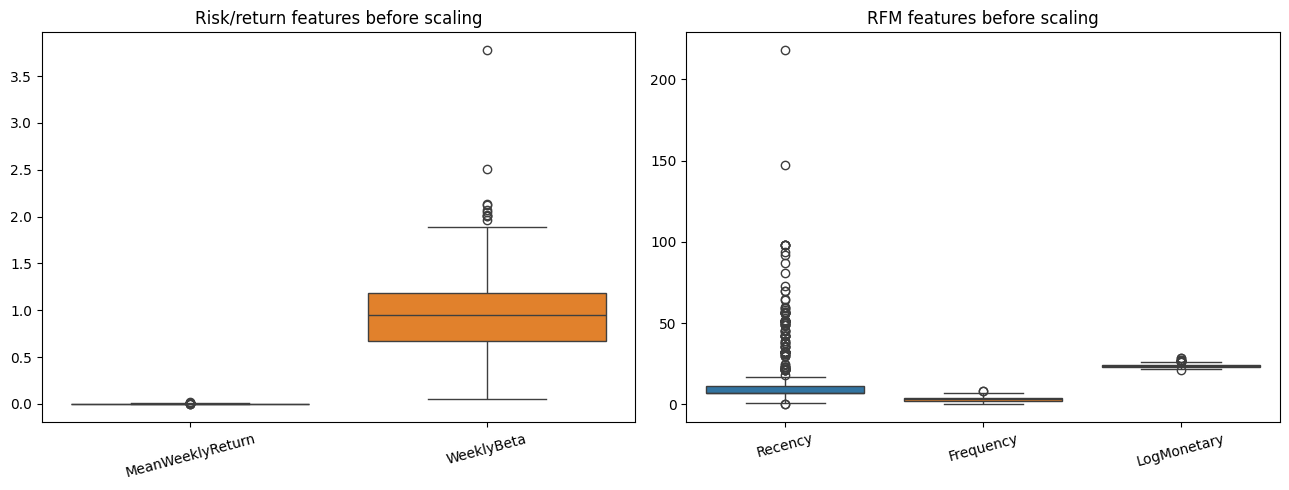

Risk matrix: (488, 2) | RFM matrix: (488, 3)


In [9]:
risk_cols = ["MeanWeeklyReturn", "WeeklyBeta"]
rfm_cols = ["Recency", "Frequency", "LogMonetary"]

risk_X = features[risk_cols].copy()
rfm_X = features[["Recency", "Frequency", "Monetary"]].copy()
rfm_X["LogMonetary"] = np.log1p(rfm_X["Monetary"])
rfm_X = rfm_X[rfm_cols].copy()

assert np.isfinite(risk_X.to_numpy()).all()
assert np.isfinite(rfm_X.to_numpy()).all()

print("Risk/return summary:")
display(risk_X.describe().round(4))
print("RFM summary:")
display(rfm_X.describe().round(4))
print("Risk/return skewness:")
display(risk_X.skew().to_frame("Skewness").round(3))
print("RFM skewness:")
display(rfm_X.skew().to_frame("Skewness").round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=risk_X, ax=axes[0])
axes[0].set_title("Risk/return features before scaling")
axes[0].tick_params(axis="x", rotation=15)
sns.boxplot(data=rfm_X, ax=axes[1])
axes[1].set_title("RFM features before scaling")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(FIGURES / "feature_outliers.png", dpi=300)
plt.show()

risk_scaler = StandardScaler()
rfm_scaler = StandardScaler()
risk_scaled = risk_scaler.fit_transform(risk_X)
rfm_scaled = rfm_scaler.fit_transform(rfm_X)

pd.DataFrame(risk_scaled, index=features.index, columns=risk_cols).to_csv(TABLES / "risk_scaled_features.csv")
pd.DataFrame(rfm_scaled, index=features.index, columns=rfm_cols).to_csv(TABLES / "rfm_scaled_features.csv")

print("Risk matrix:", risk_scaled.shape, "| RFM matrix:", rfm_scaled.shape)

## 9. Compare Ward and K-means for k = 2 to 8 (Tasks 2.2–2.3)

To select `k` consider silhouette, cluster-size balance, profile separation, interpretability and the dendrogram. The profile output below is in original units to support interpretation.

Cluster-count comparison:


,Features,Method,k,Silhouette,SmallestCluster,LargestCluster,SmallestClusterPct,LargestClusterPct,Inertia
15,RFM,KMeans,2,0.424,68,420,13.934,86.066,1070.481
17,RFM,KMeans,3,0.327,63,275,12.910,56.352,798.545
19,RFM,KMeans,4,0.341,61,212,12.500,43.443,611.848
21,RFM,KMeans,5,0.358,11,198,2.254,40.574,516.471
23,RFM,KMeans,6,0.340,11,138,2.254,28.279,439.487
25,RFM,KMeans,7,0.342,1,138,0.205,28.279,388.161
27,RFM,KMeans,8,0.350,1,139,0.205,28.484,343.416
14,RFM,Ward,2,0.386,80,408,16.393,83.607,NaN
16,RFM,Ward,3,0.260,80,226,16.393,46.311,NaN
18,RFM,Ward,4,0.250,43,183,8.811,37.500,NaN


Candidate cluster profiles:


,Features,Method,k,Cluster,MeanWeeklyReturn_count,MeanWeeklyReturn_mean,MeanWeeklyReturn_median,WeeklyBeta_count,WeeklyBeta_mean,WeeklyBeta_median,Recency_count,Recency_mean,Recency_median,Frequency_count,Frequency_mean,Frequency_median,Monetary_count,Monetary_mean,Monetary_median
0,RiskReturn,Ward,2,1,396.0,0.002,0.002,396.0,0.899,0.885,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,RiskReturn,Ward,2,2,92.0,0.006,0.006,92.0,1.298,1.218,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,RiskReturn,KMeans,2,1,143.0,0.005,0.005,143.0,1.350,1.278,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,RiskReturn,KMeans,2,2,345.0,0.002,0.002,345.0,0.818,0.841,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,RiskReturn,Ward,3,1,212.0,0.002,0.003,212.0,0.637,0.632,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,RiskReturn,Ward,3,2,92.0,0.006,0.006,92.0,1.298,1.218,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,RiskReturn,Ward,3,3,184.0,0.002,0.002,184.0,1.200,1.089,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,RiskReturn,KMeans,3,1,166.0,0.001,0.001,166.0,1.139,1.081,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,RiskReturn,KMeans,3,2,203.0,0.003,0.003,203.0,0.632,0.622,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,RiskReturn,KMeans,3,3,119.0,0.006,0.005,119.0,1.326,1.221,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Full candidate profiles saved to CSV.


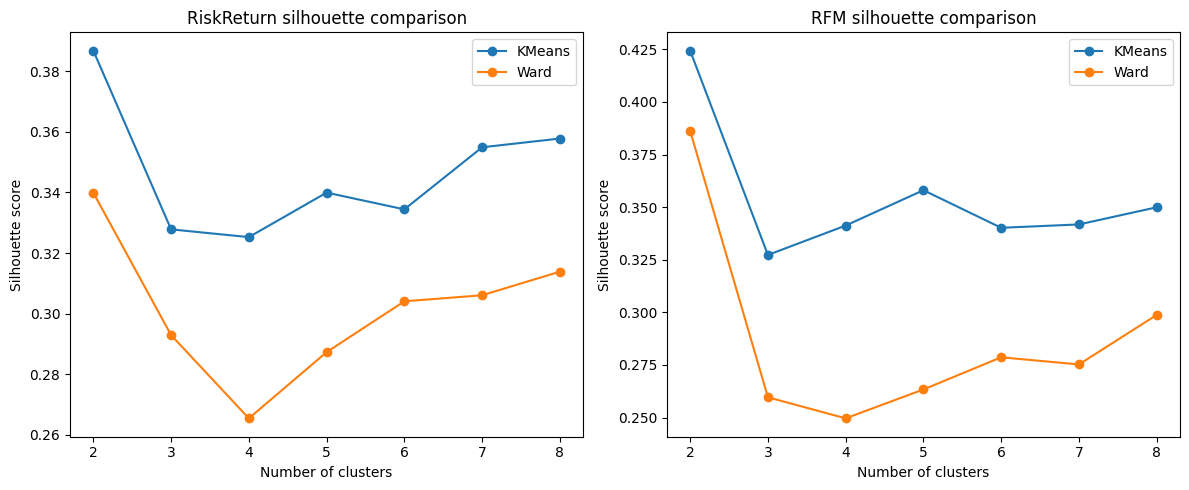

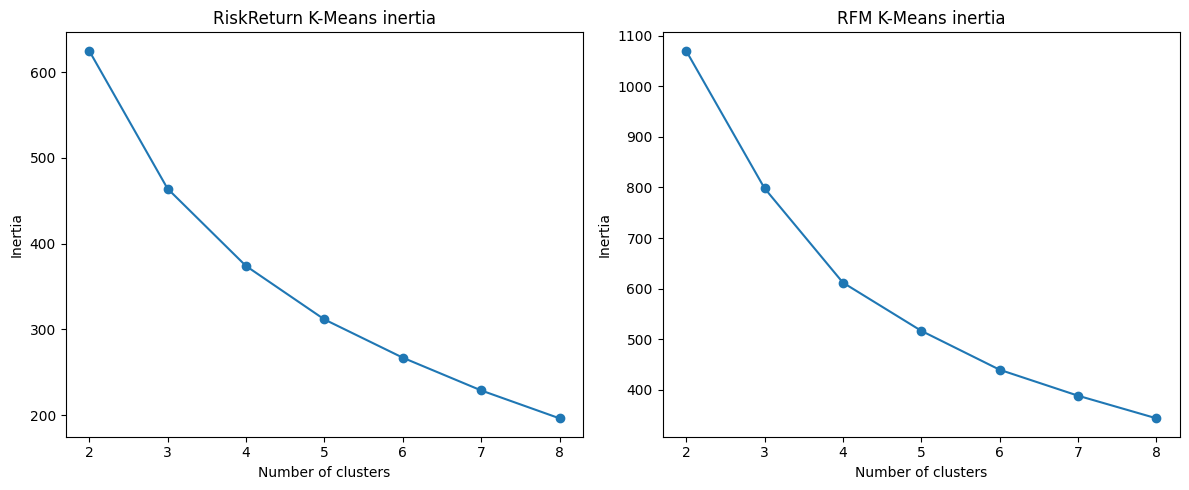

In [10]:
MIN_K, MAX_K = 2, 8
comparison_rows = []
candidate_profiles = []
candidate_labels = {}

def evaluate_cluster_counts(X, feature_name, profile_data):
    max_candidate = min(MAX_K, len(X) - 1)

    for k in range(MIN_K, max_candidate + 1):
        models = [
            ("Ward", AgglomerativeClustering(n_clusters=k, linkage="ward")),
            ("KMeans", KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20))
        ]

        for method, model in models:
            labels = model.fit_predict(X)
            candidate_labels[(feature_name, method, k)] = labels
            sizes = pd.Series(labels).value_counts()

            comparison_rows.append({
                "Features": feature_name,
                "Method": method,
                "k": k,
                "Silhouette": silhouette_score(X, labels),
                "SmallestCluster": int(sizes.min()),
                "LargestCluster": int(sizes.max()),
                "SmallestClusterPct": sizes.min() / len(labels) * 100,
                "LargestClusterPct": sizes.max() / len(labels) * 100,
                "Inertia": model.inertia_ if method == "KMeans" else np.nan
            })

            profile_frame = profile_data.copy()
            profile_frame["Cluster"] = labels + 1
            profile = profile_frame.groupby("Cluster").agg(["count", "mean", "median"])
            profile.columns = [f"{col}_{stat}" for col, stat in profile.columns]
            profile = profile.reset_index()
            profile.insert(0, "Features", feature_name)
            profile.insert(1, "Method", method)
            profile.insert(2, "k", k)
            candidate_profiles.append(profile)

evaluate_cluster_counts(risk_scaled, "RiskReturn", features[risk_cols])
evaluate_cluster_counts(rfm_scaled, "RFM", features[["Recency", "Frequency", "Monetary"]])

comparison = pd.DataFrame(comparison_rows)
candidate_profiles_df = pd.concat(candidate_profiles, ignore_index=True)

comparison.to_csv(CLUSTER_OUTPUTS / "cluster_count_comparison.csv", index=False)
candidate_profiles_df.to_csv(CLUSTER_OUTPUTS / "candidate_cluster_profiles.csv", index=False)

print("Cluster-count comparison:")
display(comparison.sort_values(["Features", "Method", "k"]).round(3))
print("Candidate cluster profiles:")
display(candidate_profiles_df.head(12).round(3))
print("Full candidate profiles saved to CSV.")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, ax in [("RiskReturn", axes[0]), ("RFM", axes[1])]:
    subset = comparison[comparison["Features"] == name]
    for method, group in subset.groupby("Method"):
        ax.plot(group["k"], group["Silhouette"], marker="o", label=method)
    ax.set_title(name + " silhouette comparison")
    ax.set_xlabel("Number of clusters")
    ax.set_ylabel("Silhouette score")
    ax.set_xticks(range(MIN_K, MAX_K + 1))
    ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "silhouette_comparison.png", dpi=300)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, ax in [("RiskReturn", axes[0]), ("RFM", axes[1])]:
    subset = comparison[
        (comparison["Features"] == name) & (comparison["Method"] == "KMeans")
    ]
    ax.plot(subset["k"], subset["Inertia"], marker="o")
    ax.set_title(name + " K-Means inertia")
    ax.set_xlabel("Number of clusters")
    ax.set_ylabel("Inertia")
    ax.set_xticks(range(MIN_K, MAX_K + 1))
plt.tight_layout()
plt.savefig(FIGURES / "kmeans_inertia.png", dpi=300)
plt.show()

## 10. Ward dendrograms (Task 2.2)

The dendrograms omit individual share labels because several hundred observations make the labels unreadable.

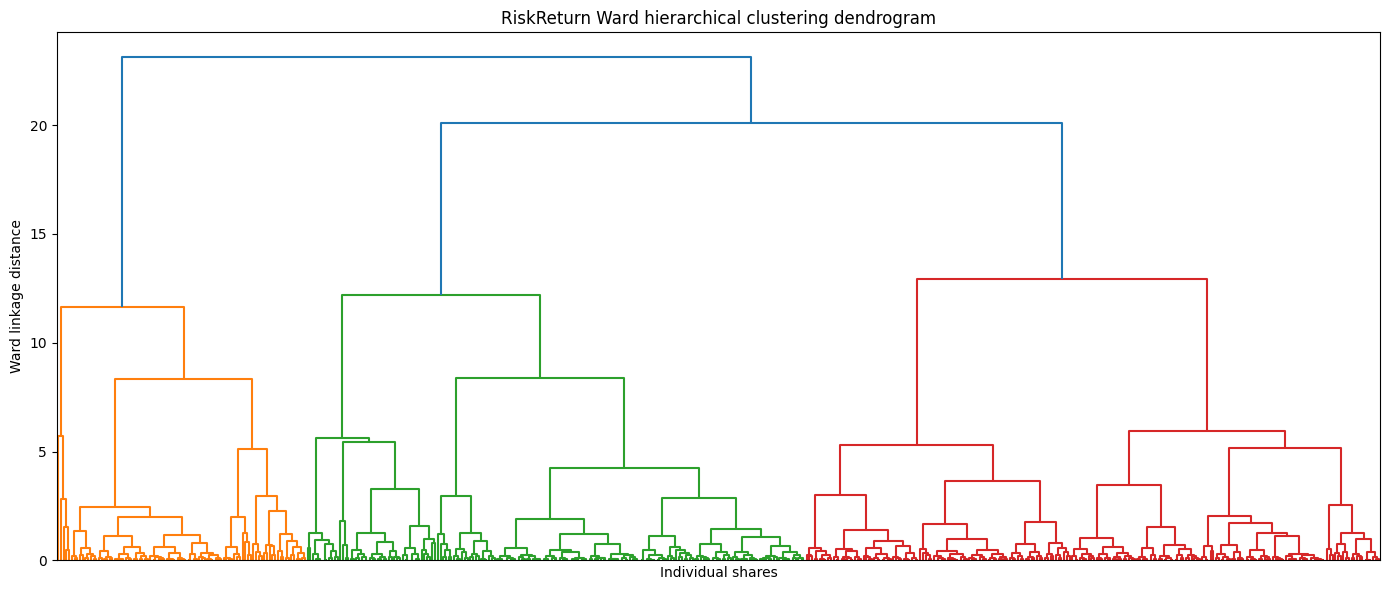

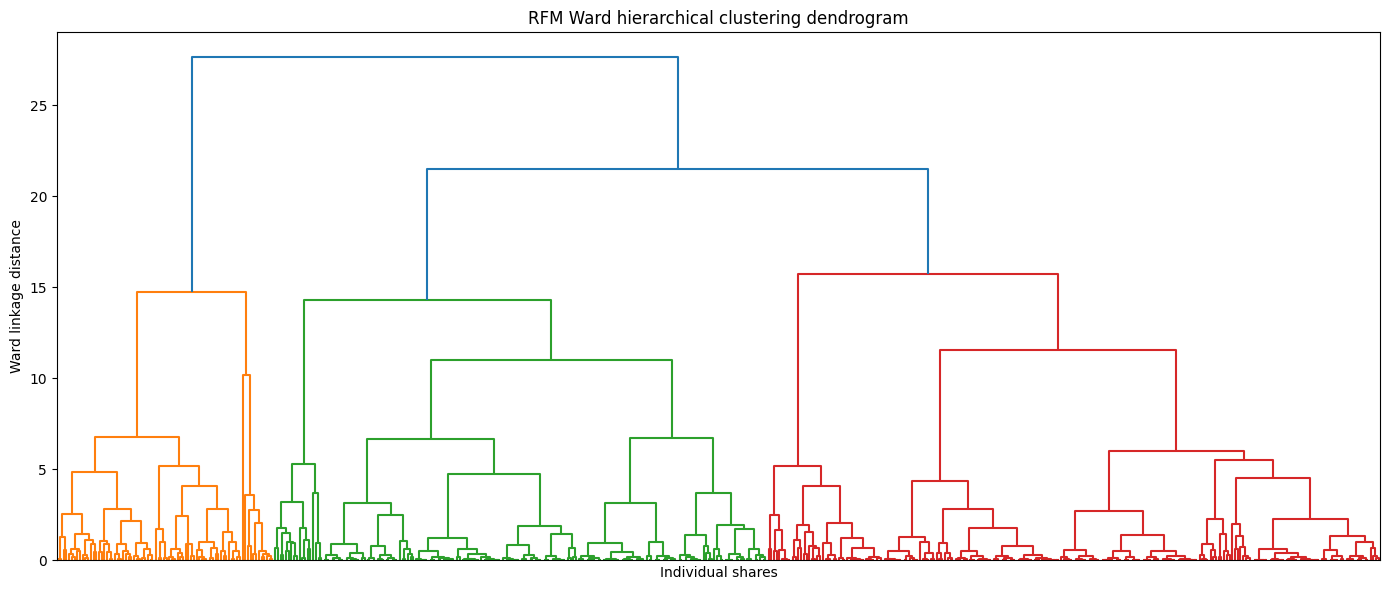

In [11]:
for X, name in [(risk_scaled, "RiskReturn"), (rfm_scaled, "RFM")]:
    tree = linkage(X, method="ward", metric="euclidean")
    plt.figure(figsize=(14, 6))
    dendrogram(tree, no_labels=True, color_threshold=None)
    plt.title(name + " Ward hierarchical clustering dendrogram")
    plt.xlabel("Individual shares")
    plt.ylabel("Ward linkage distance")
    plt.tight_layout()
    plt.savefig(FIGURES / f"{name}_dendrogram.png", dpi=300)
    plt.show()

## 11. Fit four selected clustering solutions (Task 2.4)

In [12]:
# --- MANUAL K VALUE SELECTIONS ---
K_RISK_WARD = 3
K_RISK_KMEANS = 3
K_RFM_WARD = 3
K_RFM_KMEANS = 4

# Record the selection reasons for the report summary
selection_rows = [
    {"Features": "RiskReturn", "Method": "Ward", "k": K_RISK_WARD, "Reason": "Manually chosen by analyst"},
    {"Features": "RiskReturn", "Method": "KMeans", "k": K_RISK_KMEANS, "Reason": "Manually chosen by analyst"},
    {"Features": "RFM", "Method": "Ward", "k": K_RFM_WARD, "Reason": "Manually chosen by analyst"},
    {"Features": "RFM", "Method": "KMeans", "k": K_RFM_KMEANS, "Reason": "Manually chosen by analyst"}
]

selection_summary = pd.DataFrame(selection_rows)
display(selection_summary)
selection_summary.to_csv(CLUSTER_OUTPUTS / "provisional_cluster_selection.csv", index=False)

selected_models = [
    ("Risk_Ward", risk_scaled, K_RISK_WARD, "Ward"),
    ("Risk_KMeans", risk_scaled, K_RISK_KMEANS, "KMeans"),
    ("RFM_Ward", rfm_scaled, K_RFM_WARD, "Ward"),
    ("RFM_KMeans", rfm_scaled, K_RFM_KMEANS, "KMeans")
]

assignments = features.copy()
final_cluster_profiles = []

for name, X, k, method in selected_models:
    if not MIN_K <= k <= MAX_K:
        raise ValueError(f"Invalid k for {name}: {k}. Must be between {MIN_K} and {MAX_K}.")

    model = (
        AgglomerativeClustering(n_clusters=k, linkage="ward")
        if method == "Ward"
        else KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    )

    labels = model.fit_predict(X) + 1
    assignments[name] = labels

    print(f"\n{name} — k={k}")
    display(assignments[name].value_counts().sort_index().to_frame("NumberOfShares"))
    print("Silhouette:", round(silhouette_score(X, labels - 1), 4))

    profile_columns = ["MeanWeeklyReturn", "WeeklyBeta", "Recency", "Frequency", "Monetary"]
    profile = assignments.groupby(name)[profile_columns].agg(["count", "mean", "median"])
    display(profile.round(3))

    tidy = profile.copy()
    tidy.columns = [f"{feature}_{stat}" for feature, stat in tidy.columns]
    tidy = tidy.reset_index()
    tidy.insert(0, "Model", name)
    final_cluster_profiles.append(tidy)

assignments.to_csv(CLUSTER_OUTPUTS / "cluster_assignments.csv")
final_profiles_df = pd.concat(final_cluster_profiles, ignore_index=True)
final_profiles_df.to_csv(CLUSTER_OUTPUTS / "final_cluster_profiles.csv", index=False)

risk_ari = adjusted_rand_score(assignments["Risk_Ward"], assignments["Risk_KMeans"])
rfm_ari = adjusted_rand_score(assignments["RFM_Ward"], assignments["RFM_KMeans"])

print("Ward/K-Means ARI — Risk/return:", round(risk_ari, 4))
print("Ward/K-Means ARI — RFM:", round(rfm_ari, 4))

,Features,Method,k,Reason
0,RiskReturn,Ward,3,Manually chosen by analyst
1,RiskReturn,KMeans,3,Manually chosen by analyst
2,RFM,Ward,3,Manually chosen by analyst
3,RFM,KMeans,4,Manually chosen by analyst



Risk_Ward — k=3


,NumberOfShares
Risk_Ward,
1,212
2,92
3,184


Silhouette: 0.2929


MeanWeeklyReturn               WeeklyBeta               Recency  \
                     count   mean median      count   mean median   count   
Risk_Ward                                                                   
1                      212  0.002  0.003        212  0.637  0.632     212   
2                       92  0.006  0.006         92  1.298  1.218      92   
3                      184  0.002  0.002        184  1.200  1.089     184   

                         Frequency               Monetary                \
             mean median     count   mean median    count          mean   
Risk_Ward                                                                 
1          16.104    7.0       212  2.873    3.0      212  2.355458e+10   
2          19.674    7.0        92  3.196    3.0       92  7.905329e+10   
3          15.076    7.0       184  3.038    3.0      184  3.784142e+10   

                         
                 median  
Risk_Ward                
1          1.628507e+10  
2          2.449733e+10  
3          1.470187e+10


Risk_KMeans — k=3


... (8 outputs left out)

,NumberOfShares
RFM_KMeans,
1,212
2,61
3,124
4,91


Silhouette: 0.3412


MeanWeeklyReturn               WeeklyBeta               Recency  \
                      count   mean median      count   mean median   count   
RFM_KMeans                                                                   
1                       212  0.003  0.003        212  0.940  0.931     212   
2                        61  0.003  0.003         61  0.975  1.051      61   
3                       124  0.003  0.003        124  0.965  0.922     124   
4                        91  0.003  0.003         91  1.064  1.048      91   

                          Frequency               Monetary                \
              mean median     count   mean median    count          mean   
RFM_KMeans                                                                 
1            9.311    7.0       212  2.373    2.0      212  1.524914e+10   
2           62.016   51.0        61  1.672    2.0       61  5.665233e+10   
3            9.895    7.0       124  4.540    4.0      124  1.503862e+10   
4           11.143    7.0        91  3.231    3.0       91  1.173175e+11   

                          
                  median  
RFM_KMeans                
1           1.338026e+10  
2           2.154721e+10  
3           1.280395e+10  
4           6.019928e+10

Ward/K-Means ARI — Risk/return: 0.6022
Ward/K-Means ARI — RFM: 0.2886


## 12. Two-dimensional plots and sector composition (Tasks 2.4 and 3.2)

The RFM scatterplots show Recency against Frequency. Monetary still influences the clustering in three dimensions but is not displayed in these two-dimensional projections; state this limitation in the report.

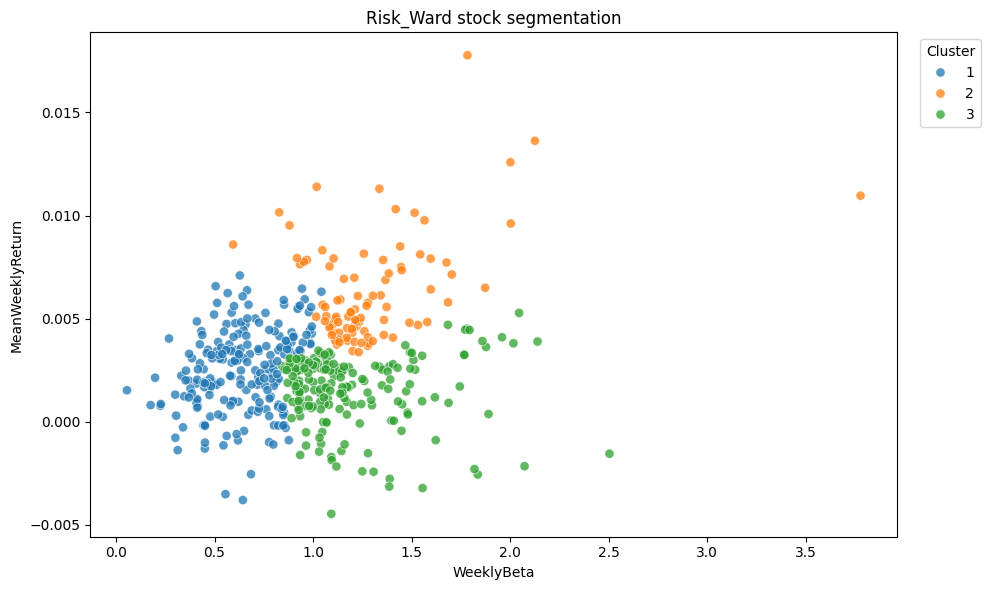

Sector composition: Risk_Ward


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Risk_Ward,,,,,,,,,,,
1,10,13,29,16,31,32,25,5,9,14,28
2,5,11,0,4,13,2,21,29,3,3,1
3,5,23,3,0,30,24,33,40,12,13,1


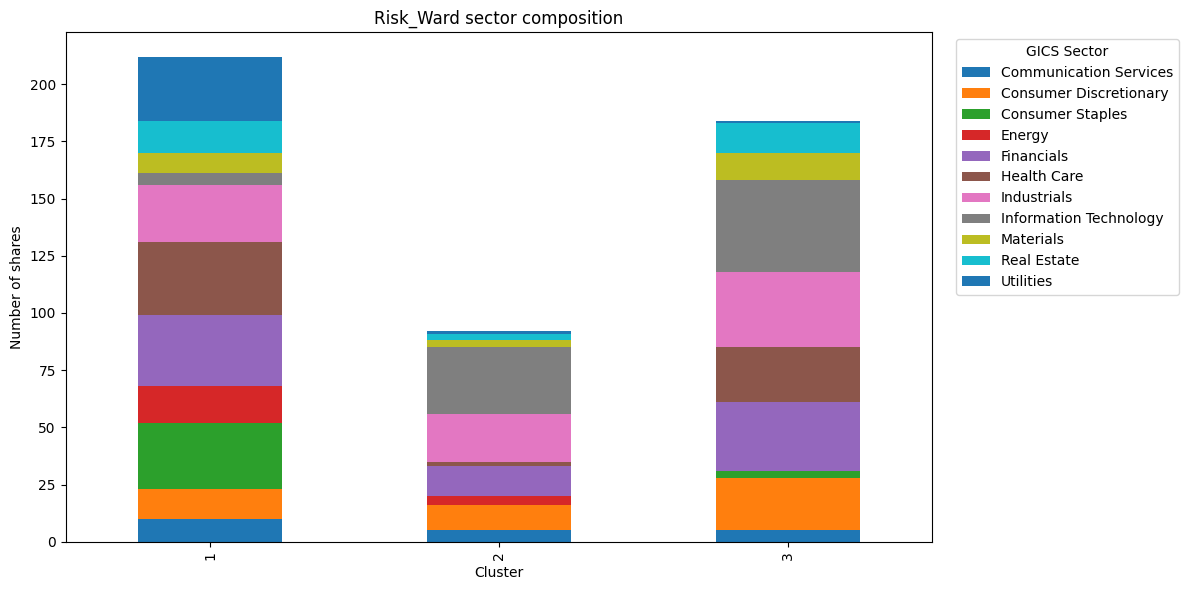

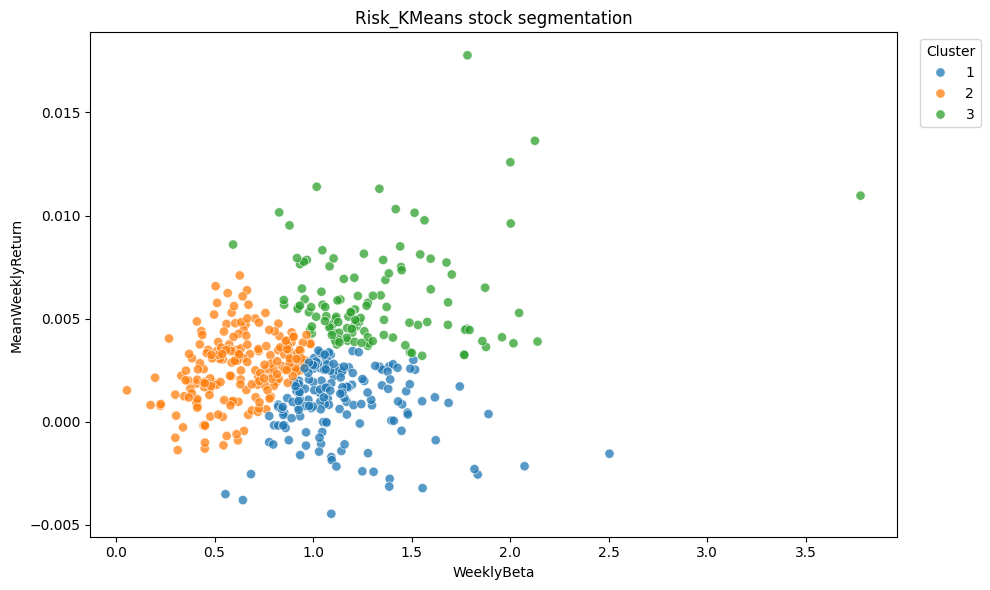

Sector composition: Risk_KMeans


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Risk_KMeans,,,,,,,,,,,
1,4,18,5,0,27,27,28,32,11,12,2
2,11,11,26,13,34,29,26,3,9,15,26
3,5,18,1,7,13,2,25,39,4,3,2


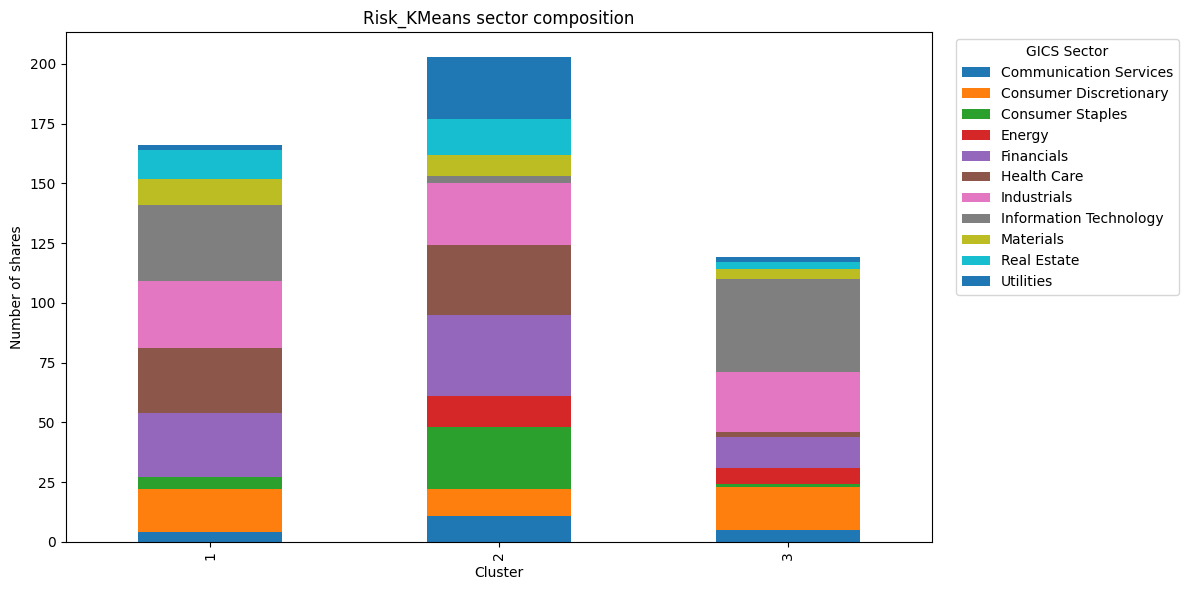

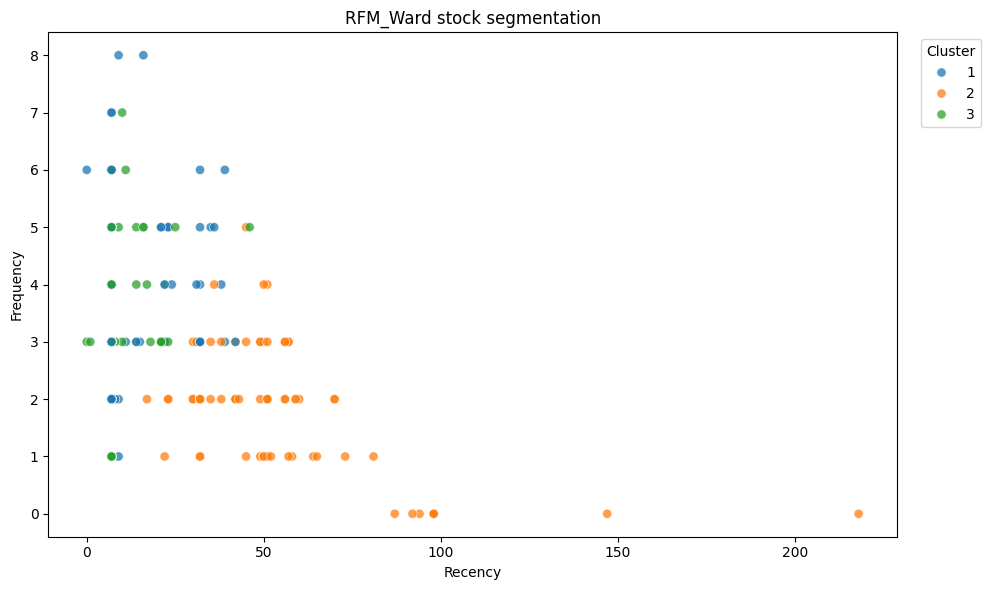

Sector composition: RFM_Ward


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
RFM_Ward,,,,,,,,,,,
1,8,15,13,7,37,28,43,22,12,24,17
2,2,9,7,1,12,7,7,19,7,0,9
3,10,23,12,12,25,23,29,33,5,6,4


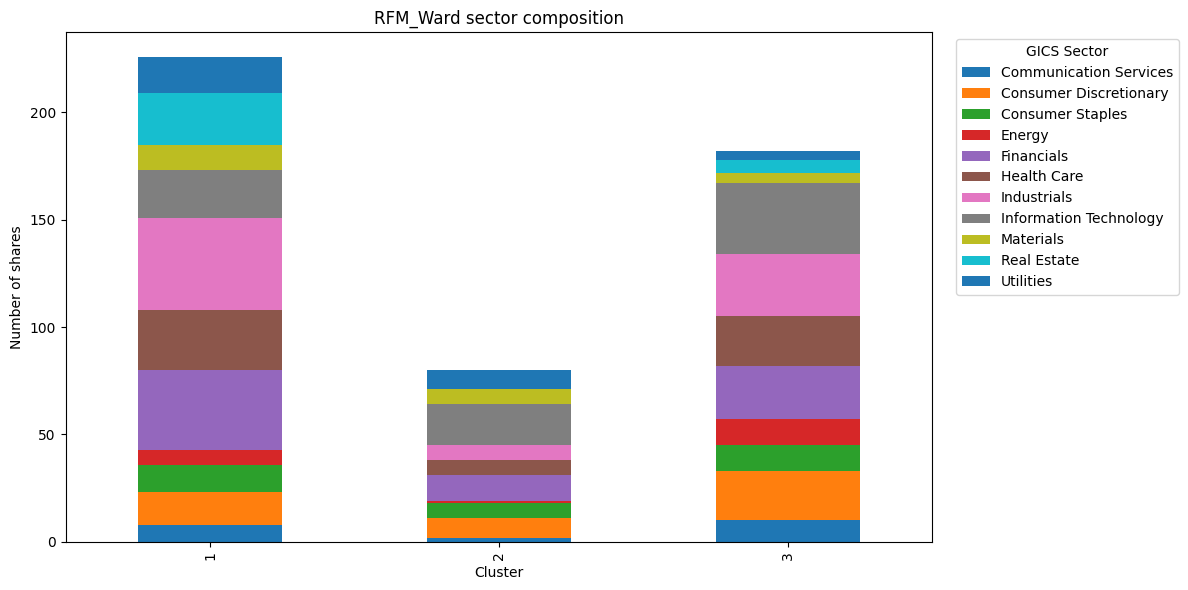

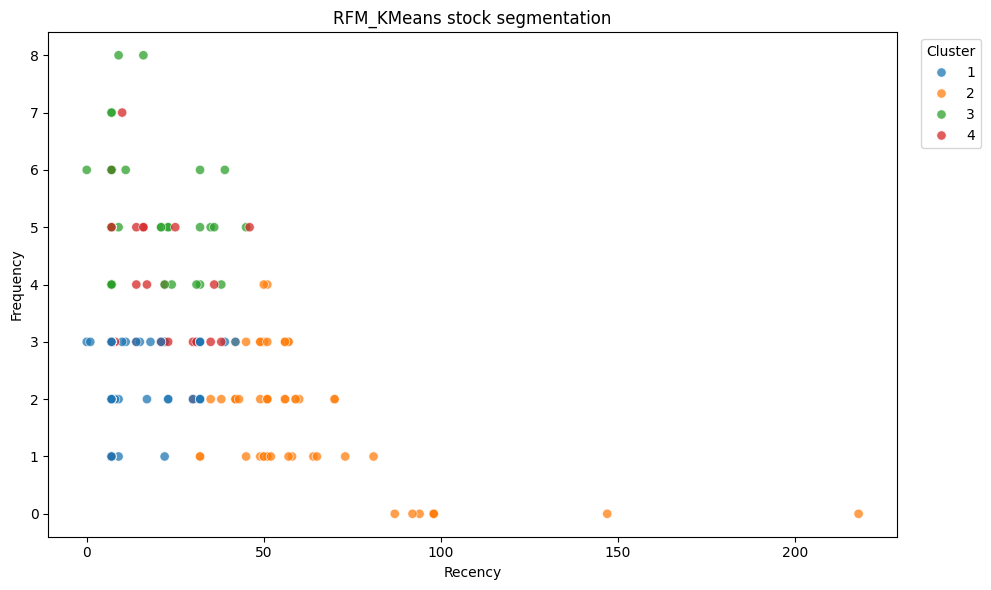

Sector composition: RFM_KMeans


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
RFM_KMeans,,,,,,,,,,,
1,4,20,12,14,33,19,44,24,12,18,12
2,2,7,5,1,8,6,4,13,6,0,9
3,6,9,8,1,20,19,24,12,5,12,8
4,8,11,7,4,13,14,7,25,1,0,1


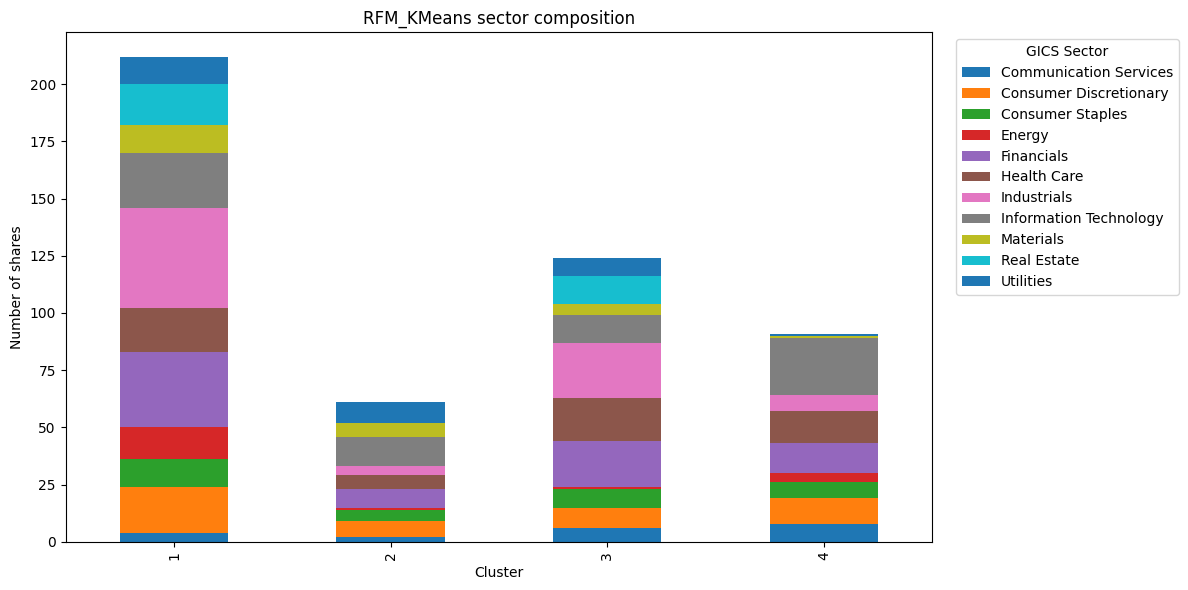

PCA explained variance: PC1=45.96%, PC2=33.50%, total=79.47%


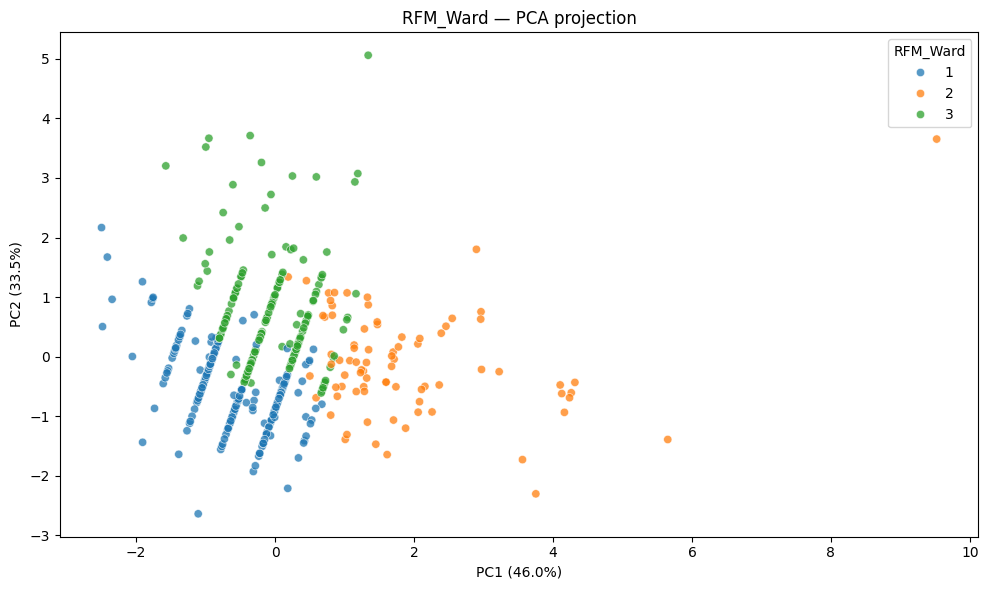

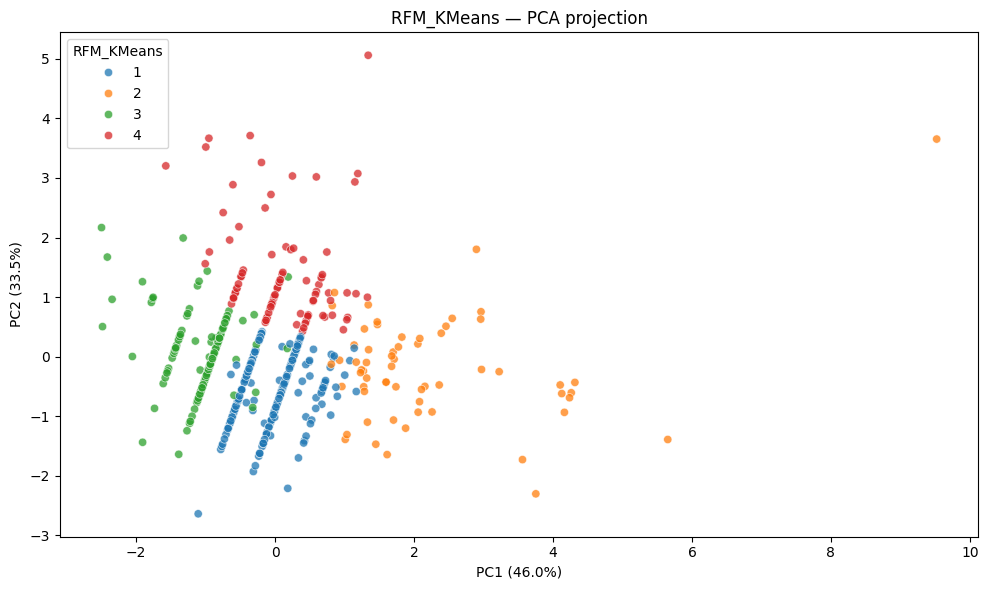

In [13]:
plot_definitions = [
    ("Risk_Ward", "WeeklyBeta", "MeanWeeklyReturn"),
    ("Risk_KMeans", "WeeklyBeta", "MeanWeeklyReturn"),
    ("RFM_Ward", "Recency", "Frequency"),
    ("RFM_KMeans", "Recency", "Frequency")
]

for label_col, x_col, y_col in plot_definitions:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=assignments, x=x_col, y=y_col,
        hue=label_col, palette="tab10", alpha=0.75, s=45
    )
    plt.title(label_col + " stock segmentation")
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(FIGURES / f"{label_col}_scatter.png", dpi=300, bbox_inches="tight")
    plt.show()

    sector_counts = pd.crosstab(assignments[label_col], assignments["Sector"])
    sector_counts.to_csv(CLUSTER_OUTPUTS / f"{label_col}_sector_counts.csv")
    print("Sector composition:", label_col)
    display(sector_counts)

    sector_counts.plot(kind="bar", stacked=True, figsize=(12, 6))
    plt.title(label_col + " sector composition")
    plt.xlabel("Cluster")
    plt.ylabel("Number of shares")
    plt.legend(title="GICS Sector", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(FIGURES / f"{label_col}_sectors.png", dpi=300, bbox_inches="tight")
    plt.show()

    sector_percentages = pd.crosstab(
        assignments[label_col], assignments["Sector"], normalize="index"
    ) * 100
    sector_percentages.to_csv(CLUSTER_OUTPUTS / f"{label_col}_sector_percentages.csv")

# PCA is only a visual projection; clustering still uses all three scaled RFM features.
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)
variance = pca.explained_variance_ratio_ * 100
print(f"PCA explained variance: PC1={variance[0]:.2f}%, PC2={variance[1]:.2f}%, total={variance.sum():.2f}%")
pca_frame = pd.DataFrame(rfm_pca, index=features.index, columns=["PC1", "PC2"])
for label_col in ["RFM_Ward", "RFM_KMeans"]:
    pca_frame[label_col] = assignments[label_col]
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=pca_frame, x="PC1", y="PC2", hue=label_col, palette="tab10", alpha=0.75)
    plt.xlabel(f"PC1 ({variance[0]:.1f}%)")
    plt.ylabel(f"PC2 ({variance[1]:.1f}%)")
    plt.title(label_col + " — PCA projection")
    plt.tight_layout()
    plt.savefig(FIGURES / f"{label_col}_pca.png", dpi=300)
    plt.show()
pca_frame.to_csv(CLUSTER_OUTPUTS / "rfm_pca_coordinates.csv")

## 13. RFM correlation and Monetary-removal sensitivity (Task 2.5)

Pearson correlation is descriptive: correlated inputs can give trading activity additional influence in Euclidean distance even after standardisation, but correlation alone does not prove that a variable dominates the clustering. The RF-only comparison uses the same shares and same `k` as the selected full-RFM Ward solution.

RFM Pearson correlations:


,Recency,Frequency,LogMonetary
Recency,1.000,-0.349,0.153
Frequency,-0.349,1.000,0.007
LogMonetary,0.153,0.007,1.000


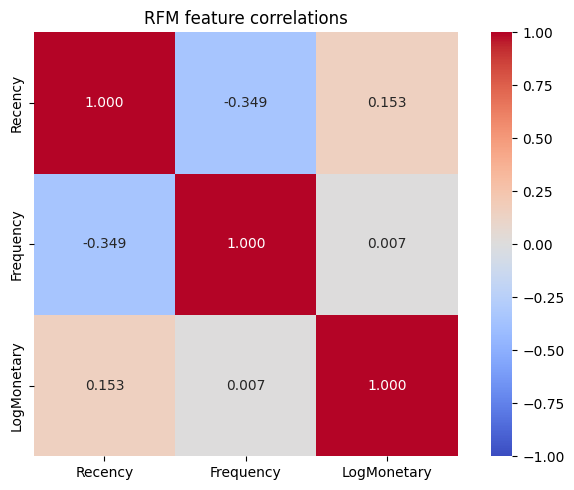

Full RFM Ward k: 3
R,F-only Ward k: 3
Same share population: True
Adjusted Rand Index: 0.2465
Full RFM cluster sizes:


,NumberOfShares
RFM_Ward,
1,226
2,80
3,182


R,F-only cluster sizes:


,NumberOfShares
RF_Ward_NoMonetary,
1,90
2,274
3,124


Monetary profiles under full RFM Ward:


,count,mean,median
RFM_Ward,,,
1,226,1.103938e+10,1.024138e+10
2,80,5.114064e+10,2.307323e+10
3,182,6.946782e+10,3.463367e+10


Monetary profiles under R,F-only Ward:


,count,mean,median
RF_Ward_NoMonetary,,,
1,90,4.657349e+10,2.057060e+10
2,274,3.918602e+10,1.495656e+10
3,124,3.468316e+10,1.804705e+10


In [14]:
correlations = rfm_X.corr(method="pearson")
print("RFM Pearson correlations:")
display(correlations.round(3))
correlations.to_csv(CLUSTER_OUTPUTS / "rfm_correlations.csv")

plt.figure(figsize=(7, 5))
sns.heatmap(correlations, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("RFM feature correlations")
plt.tight_layout()
plt.savefig(FIGURES / "rfm_correlations.png", dpi=300)
plt.show()

rf_only = features[["Recency", "Frequency"]].copy()
assert rf_only.index.equals(features.index)

rf_scaler = StandardScaler()
rf_scaled = rf_scaler.fit_transform(rf_only)

rf_only_model = AgglomerativeClustering(n_clusters=K_RFM_WARD, linkage="ward")
assignments["RF_Ward_NoMonetary"] = rf_only_model.fit_predict(rf_scaled) + 1

ari_monetary = adjusted_rand_score(
    assignments["RFM_Ward"], assignments["RF_Ward_NoMonetary"]
)

print("Full RFM Ward k:", K_RFM_WARD)
print("R,F-only Ward k:", K_RFM_WARD)
print("Same share population:", assignments.index.equals(features.index))
print("Adjusted Rand Index:", round(ari_monetary, 4))

print("Full RFM cluster sizes:")
display(assignments["RFM_Ward"].value_counts().sort_index().to_frame("NumberOfShares"))
print("R,F-only cluster sizes:")
display(assignments["RF_Ward_NoMonetary"].value_counts().sort_index().to_frame("NumberOfShares"))

print("Monetary profiles under full RFM Ward:")
display(assignments.groupby("RFM_Ward")["Monetary"].agg(["count", "mean", "median"]).round(2))
print("Monetary profiles under R,F-only Ward:")
display(assignments.groupby("RF_Ward_NoMonetary")["Monetary"].agg(["count", "mean", "median"]).round(2))

sensitivity_summary = pd.DataFrame([{
    "Comparison": "Full RFM Ward vs R,F-only Ward",
    "ClusterCount": K_RFM_WARD,
    "AdjustedRandIndex": ari_monetary,
    "NumberOfShares": len(assignments)
}])
sensitivity_summary.to_csv(CLUSTER_OUTPUTS / "monetary_sensitivity_summary.csv", index=False)
assignments.to_csv(CLUSTER_OUTPUTS / "cluster_assignments_with_sensitivity.csv")

## 14. Final checks and export inventory

The final checks verify that the four selected solutions and the Monetary-removal sensitivity solution use the same common share population.

In [15]:
cluster_columns = ["Risk_Ward", "Risk_KMeans", "RFM_Ward", "RFM_KMeans"]

assert features.index.is_unique
assert assignments.index.is_unique
assert assignments[needed].notna().all().all()
assert (assignments["RFM_Sessions"] == 60).all()
assert assignments["RF_Ward_NoMonetary"].notna().all()
assert len(assignments) == len(features)
assert (assignments["Monetary"] >= 0).all()

expected_k = {
    "Risk_Ward": K_RISK_WARD,
    "Risk_KMeans": K_RISK_KMEANS,
    "RFM_Ward": K_RFM_WARD,
    "RFM_KMeans": K_RFM_KMEANS
}
for column, k in expected_k.items():
    assert assignments[column].notna().all()
    assert assignments[column].nunique() == k

print("Study period:", START, "to", END, "(end exclusive)")
print("Observation date:", observation_date.date())
print("Benchmark sessions:", len(benchmark_dates))
print("Requested tickers:", len(tickers))
print("Validated tickers:", len(valid_tickers))
print("Final common clustering population:", len(assignments))
print("Selected k values:", expected_k)

print("\nFinal cluster sizes:")
for column in cluster_columns:
    print(column, assignments[column].value_counts().sort_index().to_dict())

print("\nProject files:")
for path in sorted(PROJECT.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(PROJECT)} — {path.stat().st_size:,} bytes")

print("\nAll final checks passed.")

Study period: 2021-01-01 to 2025-01-01 (end exclusive)
Observation date: 2024-12-27
Benchmark sessions: 1005
Requested tickers: 503
Validated tickers: 488
Final common clustering population: 488
Selected k values: {'Risk_Ward': 3, 'Risk_KMeans': 3, 'RFM_Ward': 3, 'RFM_KMeans': 4}

Final cluster sizes:
Risk_Ward {1: 212, 2: 92, 3: 184}
Risk_KMeans {1: 166, 2: 203, 3: 119}
RFM_Ward {1: 226, 2: 80, 3: 182}
RFM_KMeans {1: 212, 2: 61, 3: 124, 4: 91}

Project files:
cache/metadata/analysis_metadata.json — 1,169 bytes
cache/metadata/cache_manifest.json — 6,402 bytes
cache/raw/adjusted_close.csv — 9,049,420 bytes
cache/raw/close.csv — 8,857,990 bytes
cache/raw/constituents.csv — 19,363 bytes
cache/raw/dividends.csv — 2,013,982 bytes
cache/raw/stock_splits.csv — 2,006,625 bytes
cache/raw/volume.csv — 3,946,950 bytes
outputs/clustering/RFM_KMeans_sector_counts.csv — 287 bytes
outputs/clustering/RFM_KMeans_sector_percentages.csv — 954 bytes
outputs/clustering/RFM_Ward_sector_counts.csv — 260 byte